# Exploration of Making a Complete Reactor Mesh with MOOSE
Using the example of a 15x15 cylindrical BWR core

## Goal
Explore how to use the MOOSE reactor module's mesh builder to create a model of a BWR reactor core, usable by OPENMC, NEKRS, and MOOSE

### Learning Objectives
1. Understand how to create different core elements

2. Learn how to break down a complex mesh into workable pieces

3. Learn how to account for differing mesh element types

4. Learn how to Prepare a mesh for use by cardinal solvers, such as NEKRS, OPENMC, and other MOOSE modules

## Functions
Execute the following code cell to declare any needed functions and global variables

In [25]:
import subprocess as sp
import tempfile as tp
import os
import pyvista as pv

c_list=["lawn_green","slate_gray","silver","blue","light_cadmium_yellow","light_cadmium_yellow","light_cadmium_yellow","light_cadmium_yellow","light_cadmium_yellow","light_cadmium_yellow"]

c_dict={
  "fuel":c_list[0],
  "cladding":c_list[1],
  "control_rod":c_list[2],
  "water":c_list[3],
  "dummy":c_list[4]
}

Text_sections=["""""","""[Mesh]""","""[]"""]
def gather_sectors(tlist):
  otext="".join(Text_sections)
  return otext
def run_cardinal_file(code):
  oname="workingoutput.e"
  with tp.TemporaryDirectory(ignore_cleanup_errors=True) as work_dir:
    ifileloc = os.path.join(work_dir,"inputfile.i")
    ofileloc = os.path.join(work_dir, oname)

    with open(ifileloc,"w") as ifile:
      ifile.write(code)

    sp.run(['cardinal-opt','-i',ifileloc,'--mesh-only',ofileloc],check=True)
    ofilereader=pv.get_reader(ofileloc)
    composite_mesh = ofilereader.read()

    # Exodus files read into a MultiBlock mesh structure.
    # The actual elements blocks are typically grouped under the first block or direct keys.
    element_blocks = composite_mesh["Element Blocks"]

    pl = pv.Plotter()

    # Iterate through the block names inside the loaded multi-block mesh
    for i, block_name in enumerate(element_blocks.keys()):
      # Extract the specific mesh block object
      block_mesh = element_blocks[block_name]

      # Safe fallback if your color list is shorter than the number of blocks
      #color = c_list[i] if i < len(c_list) else "white"
      color = c_dict[block_name] if block_name in c_dict else "white"
      # Add this individual block mesh to the plotter with its color
      pl.add_mesh(block_mesh, color=color, label=block_name)

    pl.add_legend() # Optional: displays your labels
    pl.show(jupyter_backend="static")
def run_code(vb=False):
  combotxt=gather_sectors(Text_sections)
  if vb:
    print(combotxt)
  run_cardinal_file(combotxt)


# Overview
## Context
We are creating the mesh of a BWR, which means that we need to construct a core consisting of fuel bundles and control rods. Fuel bundles consist of a set of fuel pins, or vertical cylinders of fuel surrounded by cladding, and water pins, or hollow pins made of cladding to allow water to better traverse the middle of the bundles. This mesh is more simplistic, so we are not implementing the "proper" fuel bundle structure with holder plates/structures, just the pins.

## Architecture

### 1. 4 components
The goal is to have a mesh that is complex in geometry, but simple in the number of materials and structures we are actually simulating.

To differeniate the four mesh components outlined in the context, we can use something called subdomains.

Subdomains are subsets of the geometry of the Mesh, they will allow us to manipulate the mesh easier, and to easily tell the simulator where the coolant is, where the fuel is, what dimensions the cladding has, etc.

Subdomains have a plaintext name and a numerical ID. Here is the ID mapping for today

|Subdomain Name|ID|Description|
|--------------|--|-----------|
|fuel|1|All fuel elements|
|cladding|2|All fuel cladding|
|control_rod|3|All control rods in one group|
|water|4|All the water surrounding the pins and control rods|
|dummy|6|Used for storing Dummy space, or elements needed to fufill certain constructor requirements, will be removed from final mesh|

## Layout
We will break this mesh down into distinct sections, for ease of understanding what exactly we are doing
### 1. Setup substitution variables
&ensp;&ensp;a. Setup constants

&ensp;&ensp;b. Setup derived variables

### 2. Create the Cruciform Control Rods
&ensp;&ensp;a. Create the control rod sub sections for each of construction with simple shapes

&ensp;&ensp;b. Merge these subsections in one combined Cruciform_Mesh


### 3. Create the pins for the bundle
&ensp;&ensp;a. Create Fuel Pins

&ensp;&ensp;b. Create the Water Pins


### 4. Create the Fuel bundles
&ensp;&ensp;a. Create the Bundle Mesh

&ensp;&ensp;b. Fix Mesh element types


### 5. Create fuel assemblies 
&ensp;&ensp;a. Create the quad bundle assembly

&ensp;&ensp;b. Create the single bundle assemblies

&ensp;&ensp;c. Create the double bundle assemblies


### 6. Create Core Assembly
&ensp;&ensp;a. Create the rough core mesh

&ensp;&ensp;b. Clear all dummy elements from core

&ensp;&ensp;c. Repair mesh boundaries for use by Cardinal

&ensp;&ensp;d. Add core periphery

&ensp;&ensp;e. Finish cleaning boundaries for Cardinal use

# 1. Setting up substitution variables

### Setting Basic Constants and Dimensions
We will need to define several very important basic dimensions of our reactor, such as how big a fuel pin is, how thick the cladding is, etc.


In [26]:
constants="""
# Control Rod Dimensions

#Rcr is the half-width of the control rod arms
rcr = 1.5

#Wpin is the width of the enclosing square of a pin
Wpin = 5.0

#Rpin is the half-width of the enclosing square of a pin
Rpin = '${fparse Wpin*0.5}'

#Wbundle is the width of one square fuel bundle, which is an 8x8 pin square
Wbundle = '${fparse Wpin*8}'

#Rbundle is the half-width a fuel-bundle
Rbundle = '${fparse Wbundle*0.5}'

#L1 is the length of the rod from the center
#L1 is ideally 2rcr + 6*wpin so it ends up roughly 2/3 of the fuel bundles,
#as there should be rcr between the fuel bundles and the control rod,
# so add two rcr and 6 wpin
l1 = '${fparse 2*rcr+6*Wpin}'

#Wassem is the width of the Bundle Assembly meshes
#It should be the width of two fuel bundles, plus the width of the control rod arm, which is 2*rcr, plus the gap between the control rod and bundles, which is 2*rcr, plus 1 unit of headroom around the outside, so +2
Wassem = '${fparse 2*Wbundle + 4*rcr + 2}'

#Rassem is the half-width of the bundle assembly meshes
Rassem = '${fparse Wassem*0.5}'

#HRassem is the quarter-width of the bundle assemblies
HRassem = '${fparse Rassem*0.5}'

#Wsingle is the width of the surround for a single bundle for edges of the core, which is the width of a bundle +2 for a surround of width 1
Wsingle = '${fparse Wbundle+2}'

#Dbundle is the offset between the center of an assembly and the center of a bundles in one dimension
Dbundle = '${fparse 2*rcr+Rbundle}'

#Doffset is the offset used to create dummy assembly elements
Doffset = '${fparse Rassem-Wsingle}'

#WGap: For double-bundle assemblies, we need to know width of the gap between fuel bundles so we can fill it in
Wgap = '${fparse (2*rcr)-((Wsingle-Wbundle)/2)}'

#Soffset: When building the dummy mesh around Single and Double bundles, we need an offset to account for the fact there is no control rod
Soffset = '${fparse Rassem-Wsingle}'

#Boffset: We need the offset from the origin for the center of the bundles
Boffset = '${fparse Rbundle+2*rcr}'

#Bpitch: We need the pitch, or distance, between two bundle centers
Bpitch = '${fparse Boffset*2}'

#We need to make sure the width of each subsection of the edges of matching meshes work

#npitch is the goal node pitch
npitch = 2.0 #Units between nodes

#nquad is number of sectors for quad-bundle assembly sides
nquad = '${fparse Wassem/npitch}'

#nsingle is the number of sectors for a single fuel element surround
nsingle = '${fparse Wsingle/npitch}'

#ndummy is the number of sectors to add when creating dummy parts of double and single assemblies
ndummy = '${fparse nquad-1}'

#the control rods have their own node numbers
#number of nodes for each dimension of control rod
#ncrs is nodes on the short side of the control rod
ncrs = 5
#ncrl is nodes on long side of control rod
ncrl = 20

#We need to also set some values for that outer periphery

#Rper is the radius of the periphery, which should be 15 assembly half-widths wide, plus 1 more to ensure it can fully enclose the core
Rper = '{fparse Rassem*16}'
 """
Text_sections[0]=constants

# 2. Making the Control Rod Mesh

## Approach
### 1. Create center of cross shape
&ensp;&ensp;Create a user block called central_hub, it will be a GeneratedMeshGenerator

&ensp;&ensp;It will have x and y max of rcr, and x and y min of -rcr. 

&ensp;&ensp;It will have both node counts set to ncrs

&ensp;&ensp;We must also set it to subdomain control_rod, ID 3

### 2. Create horizontal sections
&ensp;&ensp;a. First make the "standard" section

&ensp;&ensp;&ensp;&ensp; This look very similar to central_hub, but it will be called blade_horizontal

&ensp;&ensp;&ensp;&ensp;The only major difference is that the x nodes are now ncrl, and the xmax is now l1

&ensp;&ensp;b. Now to make the opposite section

&ensp;&ensp;&ensp;&ensp;Call this block blade_horizontal_flipped

&ensp;&ensp;&ensp;&ensp;It will be block type SymmetryTransformGenerator, which allows us to reflect a mesh across a plane in 3d space

&ensp;&ensp;&ensp;&ensp;We will just reflect it across the y-axis, or with normal vector 1 0 0

&ensp;&ensp;c. Make a third user block

&ensp;&ensp;&ensp;&ensp;We need this because the boundaries of the blade_horizontal are flipped L/R, that is: The boundary called "left" is on the right, and the<br> &ensp;&ensp;&ensp;&ensp;boundary called "right" is on the left

&ensp;&ensp;&ensp;&ensp;We can fix this with a RenameBoundaryGenerator

&ensp;&ensp;&ensp;&ensp;This block will be called blade_horizontal_cross, as it is now ready to be used
### 3. Join horizontal sections to center
&ensp;&ensp;Now we will create a block called blade_horizontal_combo

&ensp;&ensp;This will be a StitchMeshGenerator, or a kind of block that allows us to combine meshes that sit next to each other into one larger mesh

&ensp;&ensp;We will combine the center block and the two horizontal arms
### 4. Create vertical sections
&ensp;&ensp;We will now follow the same steps as we did to make the horizontal sections, but flipping which direction we use l1 for, and which is ncrs and<br> &ensp;&ensp;ncrl
### 5. Create final control rod mesh
&ensp;&ensp;Now, we will use another StichMeshGenerator to combine those two vertical arms with the rest of the mesh

&ensp;&ensp;The Mesh will be called cruciform_mesh

In [27]:
control_rod="""
#Center of Rod
  [central_hub]
    type = GeneratedMeshGenerator
    dim = 2
    nx = ${ncrs}
    ny = ${ncrs}
    xmin = -${rcr}
    xmax = ${rcr}
    ymin = -${rcr}
    ymax = ${rcr}
    subdomain_ids = 3
    subdomain_name = 'Control_Rod'
  []

  #One horizontal blade
  [blade_horizontal]
    type = GeneratedMeshGenerator
    dim = 2
    nx = ${ncrl}
    ny = ${ncrs}
    xmin = ${rcr} # Starts outside center piece
    xmax = ${l1} # Total length of the arm
    ymin = -${rcr} # Half-thickness of the blade
    ymax = ${rcr} # Half-thickness of the blade
    subdomain_ids = 3
    subdomain_name = 'Control_Rod'
  []

  #Mirror the horizontal blade
  [blade_horizontal_flipped]

    type = SymmetryTransformGenerator
    input = blade_horizontal
    mirror_point = '0.0 0.0 0.0' # A point on the mirror plane/line
    mirror_normal_vector = '1.0 0.0 0.0' # Normal vector of the mirror plane (reflects across x=-y)
  []

  #Reassign boundaries so the left and right are "correct"
  [blade_horizontal_cross]
    type = RenameBoundaryGenerator
    input = blade_horizontal_flipped
    new_boundary = 'left right'
    old_boundary = 'right left'
  []

  #Combine the two horizontal blades and the central hub
    [blade_horizontal_combo]
      type = StitchMeshGenerator
      inputs = 'blade_horizontal_cross central_hub blade_horizontal'
      stitch_boundaries_pairs = 'right left;
                                 right left'
      merge_boundaries_with_same_name = true
      clear_stitched_boundary_ids = true
    []

  # Rotate the horizontal blade by 90 degrees to make the vertical blade
    [blade_vertical]
      type = GeneratedMeshGenerator
      dim = 2
      nx = ${ncrs}
      ny = ${ncrl}
      xmin = -${rcr} # Half-thickness of the blade
      xmax = ${rcr} # Half-thickness of the blade
      ymin = ${rcr} # Starts outside center piece
      ymax = ${l1} # Total length of the arm
      subdomain_ids = 3
      subdomain_name = 'Control_Rod'
    []

  #Mirror the vertical blade
  [blade_vertical_flipped]
    # Mirrors across both axes to complete the 4 arms
    type = SymmetryTransformGenerator
    input = blade_vertical
    mirror_point = '0.0 0.0 0.0' # A point on the mirror plane/line
    mirror_normal_vector = '0.0 1.0 0.0' # Normal vector of the mirror plane (reflects across x=-y)
  []

  #Reassign boundaries so the left and right are "correct"
  [blade_vertical_cross]
    type = RenameBoundaryGenerator
    input = blade_vertical_flipped
    new_boundary = 'top bottom'
    old_boundary = 'bottom top'
  []

  #Combine the vertical blades and the previous assembly to get final control rod
  [cruciform_mesh]
    type = StitchMeshGenerator
    # setup
    # blade v
    # blade h
    # blade v cross
    inputs = 'blade_vertical blade_horizontal_combo blade_vertical_cross'
    stitch_boundaries_pairs = 'bottom top;
                               bottom top'
    merge_boundaries_with_same_name = true
    clear_stitched_boundary_ids = true
    #inputs = 'blade_horizontal_cross blade_vertical_cross'
  []

"""
if control_rod in Text_sections:
  Text_sections[Text_sections.index(control_rod)]=control_rod
else:
  Text_sections.insert(2,control_rod)



*** Warning ***
/tmp/tmp_awskjk0/inputfile.i:11.1: unused parameter 'Rpin'
/tmp/tmp_awskjk0/inputfile.i:33.1: unused parameter 'HRassem'
/tmp/tmp_awskjk0/inputfile.i:39.1: unused parameter 'Dbundle'
/tmp/tmp_awskjk0/inputfile.i:42.1: unused parameter 'Doffset'
/tmp/tmp_awskjk0/inputfile.i:45.1: unused parameter 'Wgap'
/tmp/tmp_awskjk0/inputfile.i:48.1: unused parameter 'Soffset'
/tmp/tmp_awskjk0/inputfile.i:54.1: unused parameter 'Bpitch'
/tmp/tmp_awskjk0/inputfile.i:65.1: unused parameter 'nsingle'
/tmp/tmp_awskjk0/inputfile.i:68.1: unused parameter 'ndummy'
/tmp/tmp_awskjk0/inputfile.i:80.1: unused parameter 'Rper'
 Mesh Information:
  elem_dimensions()={2}
  elem_default_orders()={FIRST}
  supported_nodal_order()=1
  spatial_dimension()=2
  n_nodes()=516
    n_local_nodes()=516
  n_elem()=425
    n_local_elem()=425
    n_active_elem()=425
  n_subdomains()=1
  n_elemsets()=0
  n_partitions()=1
  n_processors()=1
  n_threads()=1
  processor_id()=0
  is_prepared()=true
  is_replicate

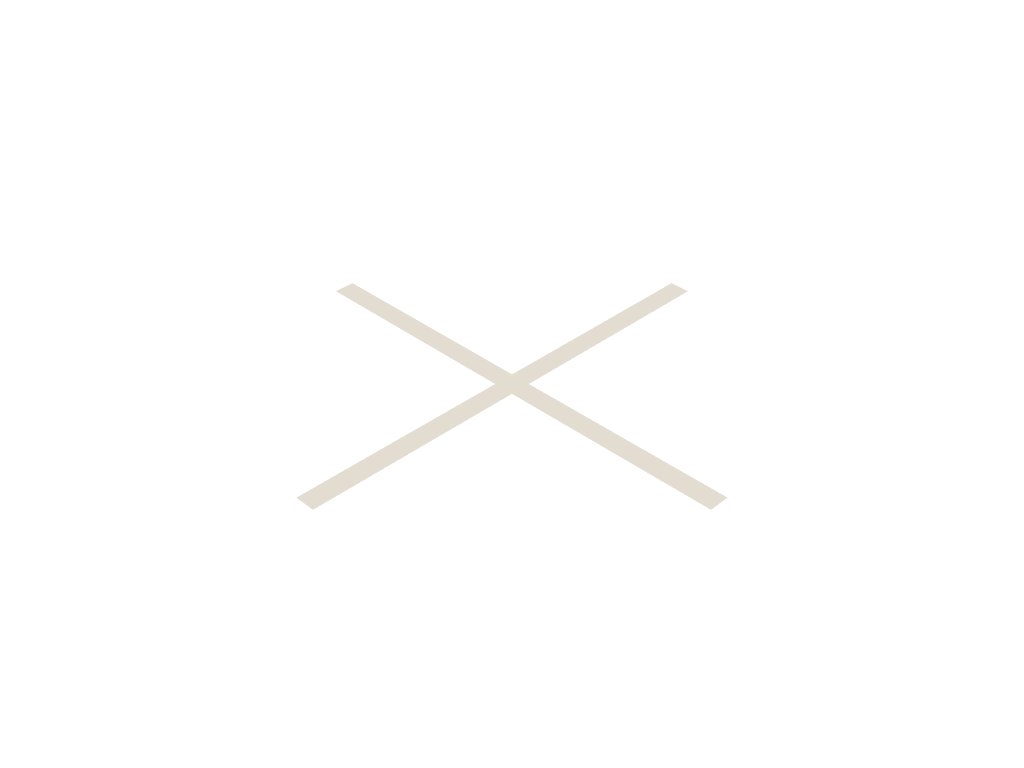

In [28]:
Text_sections.insert(3,"""final_generator=cruciform_mesh""")
run_code()

# 3. Creating the pin meshes

## Approach
### 1. Create Fuel pin
&ensp;&ensp;This will be using a new type of MeshGenerator, called <br>&ensp;&ensp;CartesianConcentricCircleAdaptiveBoundaryMeshGenerator

&ensp;&ensp;This creates a set of concentric circles, and then surrounds them with a square

&ensp;&ensp;It requires the side length of the square, called square_size

&ensp;&ensp;It also then requires the radii of the rings, which we have set to 1.8 for fuel, and 2 <br>&ensp;&ensp;for cladding

&ensp;&ensp;There will be 3 set subdomains, 1 for the inner ring, 2 for the outer ring, 4 for the <br>&ensp;&ensp;outside

### 2. Create Water pin
&ensp;&ensp;This will be using a slightly different MeshGenerator, called <br>
&ensp;&ensp;PolygonConcentricCircleMeshGenerator

&ensp;&ensp;This generator is a more abstract version than Cartesian, which allows us to <br>&ensp;&ensp;generate any outer shape we want(could be useful later for custom fuel channel <br>&ensp;&ensp;geometry)

&ensp;&ensp;We are using it as it allows us to set what kind of mesh elements we use in the <br>&ensp;&ensp;center of the circle

&ensp;&ensp;The other boundary water stuff will make geometry comprised of trapezoids, <br>&ensp;&ensp;called QUAD4. Polygon... can make QUAD4 elements in the center, but Cartesian... <br>&ensp;&ensp;enforces generating the center out of triangles, called TRI3. 

&ensp;&ensp;When MOOSE sets the final mesh, if different geometry types are under the same <br>&ensp;&ensp;subdomain, it will crash

&ensp;&ensp;The two subdomains are 4 for the background and center, and 2 for the outer ring

In [29]:
pins="""
#Create fuel pin
  [Fuel_pin]
    type = CartesianConcentricCircleAdaptiveBoundaryMeshGenerator
    num_sectors_per_side = '4 4 4 4'
    square_size = ${Wpin}
    ring_intervals = '1 1'
    ring_radii = '1.8 2'
    ring_block_ids = '1 2'
    ring_block_names = 'fuel cladding'
    background_intervals = 1
    background_block_ids = 4
    background_block_names = 'water'
  []

#Create Water pin/Water Channel
  [Water_pin]
    type = PolygonConcentricCircleMeshGenerator
    num_sides = 4
    num_sectors_per_side = '4 4 4 4'
    polygon_size = ${Rpin}
    ring_intervals = '1 1'
    ring_radii = '1.8 2'
    ring_block_ids = '4 2'
    ring_block_names = 'water cladding'
    quad_center_elements = true
    flat_side_up = true
    background_intervals = 1
    background_block_ids = 4
    background_block_names = 'water'
    quad_element_type = QUAD4
  []
"""
if pins in Text_sections:
  pass
else:
  Text_sections.insert(3,pins)



*** Warning ***
/tmp/tmpq35rh7eo/inputfile.i:33.1: unused parameter 'HRassem'
/tmp/tmpq35rh7eo/inputfile.i:39.1: unused parameter 'Dbundle'
/tmp/tmpq35rh7eo/inputfile.i:42.1: unused parameter 'Doffset'
/tmp/tmpq35rh7eo/inputfile.i:45.1: unused parameter 'Wgap'
/tmp/tmpq35rh7eo/inputfile.i:48.1: unused parameter 'Soffset'
/tmp/tmpq35rh7eo/inputfile.i:54.1: unused parameter 'Bpitch'
/tmp/tmpq35rh7eo/inputfile.i:65.1: unused parameter 'nsingle'
/tmp/tmpq35rh7eo/inputfile.i:68.1: unused parameter 'ndummy'
/tmp/tmpq35rh7eo/inputfile.i:80.1: unused parameter 'Rper'
 Mesh Information:
  elem_dimensions()={2}
  elem_default_orders()={FIRST}
  supported_nodal_order()=1
  spatial_dimension()=2
  n_nodes()=73
    n_local_nodes()=73
  n_elem()=64
    n_local_elem()=64
    n_active_elem()=64
  n_subdomains()=2
  n_elemsets()=0
  n_partitions()=1
  n_processors()=1
  n_threads()=1
  processor_id()=0
  is_prepared()=true
  is_replicated()=true

 Mesh Bounding Box:
  Minimum: (x,y,z)=(    -2.5,     

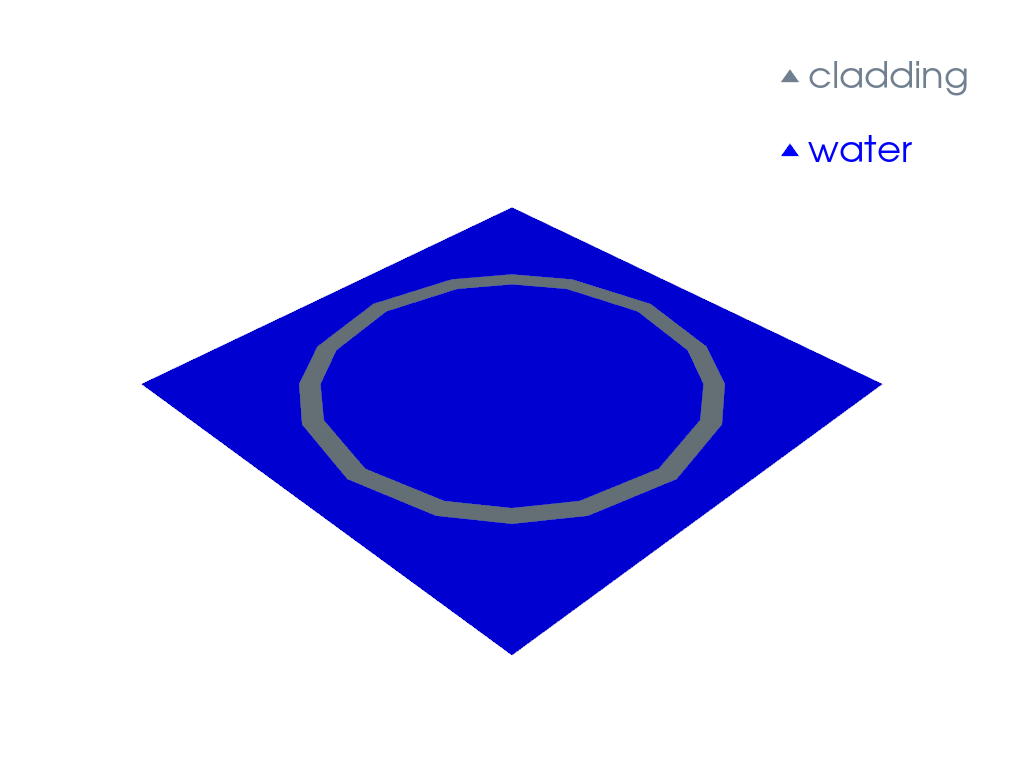



*** Warning ***
/tmp/tmp7vhf_yd7/inputfile.i:33.1: unused parameter 'HRassem'
/tmp/tmp7vhf_yd7/inputfile.i:39.1: unused parameter 'Dbundle'
/tmp/tmp7vhf_yd7/inputfile.i:42.1: unused parameter 'Doffset'
/tmp/tmp7vhf_yd7/inputfile.i:45.1: unused parameter 'Wgap'
/tmp/tmp7vhf_yd7/inputfile.i:48.1: unused parameter 'Soffset'
/tmp/tmp7vhf_yd7/inputfile.i:54.1: unused parameter 'Bpitch'
/tmp/tmp7vhf_yd7/inputfile.i:65.1: unused parameter 'nsingle'
/tmp/tmp7vhf_yd7/inputfile.i:68.1: unused parameter 'ndummy'
/tmp/tmp7vhf_yd7/inputfile.i:80.1: unused parameter 'Rper'
 Mesh Information:
  elem_dimensions()={2}
  elem_default_orders()={FIRST}
  supported_nodal_order()=1
  spatial_dimension()=2
  n_nodes()=49
    n_local_nodes()=49
  n_elem()=48
    n_local_elem()=48
    n_active_elem()=48
  n_subdomains()=3
  n_elemsets()=0
  n_partitions()=1
  n_processors()=1
  n_threads()=1
  processor_id()=0
  is_prepared()=true
  is_replicated()=true

 Mesh Bounding Box:
  Minimum: (x,y,z)=(    -2.5,     

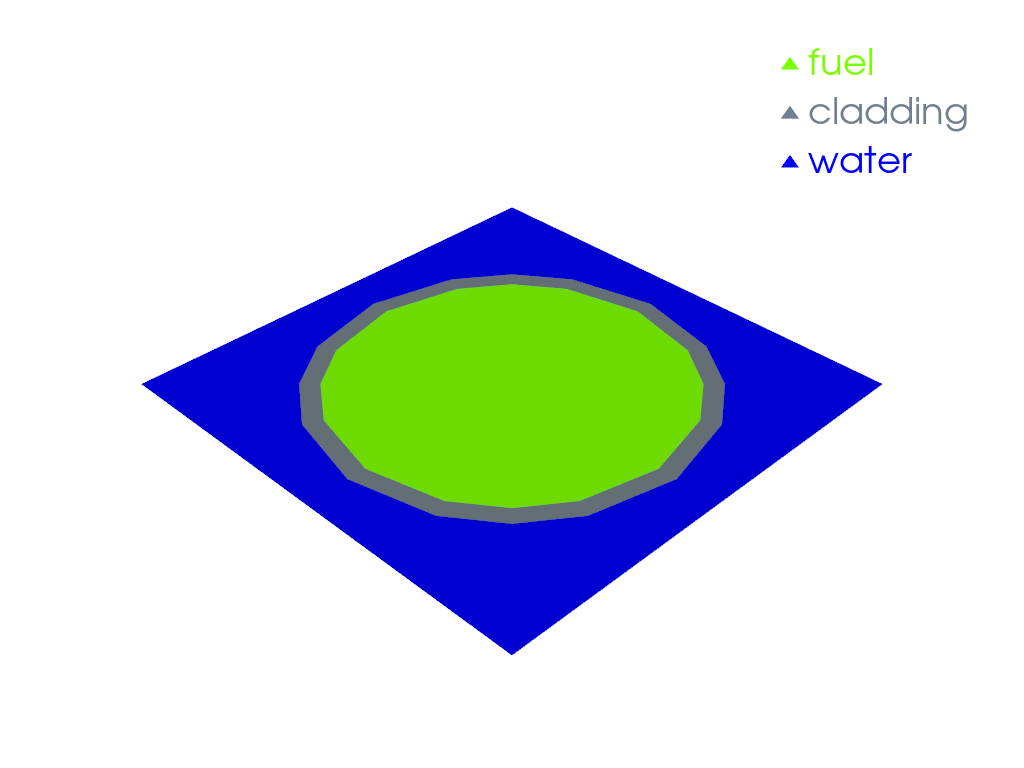

In [30]:

Text_sections[Text_sections.index("final_generator=cruciform_mesh")]="""final_generator=Water_pin"""
run_code()
Text_sections[Text_sections.index("""final_generator=Water_pin""")]="""final_generator=Fuel_pin"""
run_code()


# 4. Create fuel bundle

## Approach

### 1. Generate the bundle mesh
&ensp;&ensp;We are going to be using PatternedCartesianMeshGenerator

&ensp;&ensp;This takes input meshes, a square layout, and then makes a larger mesh by filling in the gaps and surrounding the mesh with a larger square

&ensp;&ensp;We will be using the water and fuel pin meshes here. This should be an 8x8 square of fuel pins, with 2 of the middle 4 replaced with water pins

&ensp;&ensp;The outer square size will be Wbundle

&ensp;&ensp;The block will be named Bundle_Mesh_gen

### 2. Divide into 2 sections for use
&ensp;&ensp;We now face a new issue. Even though we just made sure all of the water would be QUAD4 mesh, in later steps it must become TRI3. 

&ensp;&ensp;To accomplish this, we will separate the water and the pins from each other

&ensp;&ensp;We will use BlockToMeshConverterGenerator, which extracts a set of blocks/subdomains from a given mesh. One we will call Bundle_meshw, where we put water or block 4, the other will be called Bundle_mesho, which extracts fuel and cladding, or blocks 1 and 2

&ensp;&ensp;**NOTE:** When extracting blocks this way, it deletes all boundaries on the mesh, so make sure to account for that in your code

### 3. Set element types correctly
&ensp;&ensp;Now we will fix that extracted water mesh

&ensp;&ensp;We will apply a nice tool called ElementsToSimplicesConverter, which divides up each trapezoid into two triangles quickly and cleanly.

&ensp;&ensp;The block will be called Bundle_meshwconv
### 4. Recombine Mesh
&ensp;&ensp;Now we need to rejoin the two mesh parts together

&ensp;&ensp;We will use a combiner generator to do this

&ensp;&ensp;It is more rough than StitchMesh, but works more broadly

&ensp;&ensp;This will be called Bundle_Mesh_combined

### 5. Repair Mesh
&ensp;&ensp;After the CombinerGenerator, the mesh is left damaged

&ensp;&ensp;It has several boundaries that overlap, and some are missing altogether. We need to fix them. 

#### &ensp;&ensp;1. Add back the boundary around the outside of the mesh

&ensp;&ensp;&ensp;&ensp;We will do this by using a SideSetsFromNormalsGenerator

&ensp;&ensp;&ensp;&ensp;This works by taking normal vectors, finding the "edge" of a mesh parallel to that direction, and creating a boundary over that location

&ensp;&ensp;&ensp;&ensp;It can take a list of normal vectors

&ensp;&ensp;&ensp;&ensp;We will give it normals pointing up, down, left, and right

&ensp;&ensp;&ensp;&ensp;We will name them based on what direciton they are, pos or neg x, pos or neg y

&ensp;&ensp;&ensp;&ensp;This block will be called Bundle_Mesh_add_outer_bounds

&ensp;&ensp;&ensp;&ensp;We will then make another block, Bundle_Mesh_merge_outer_bounds

&ensp;&ensp;&ensp;&ensp;This will be a RenameBoundaryGenerator

&ensp;&ensp;&ensp;&ensp;We will rename all the outer boudnaries to one bundle_ext

#### &ensp;&ensp;2. Repair outer boundary
&ensp;&ensp;&ensp;&ensp;We will make another block called Bundle_Mesh, as this is the last step before we can use the now completed mesh

&ensp;&ensp;&ensp;&ensp;This block will be a MeshRepairGenerator, which is designed to clean up the mess CombinerGenerator left for us.

&ensp;&ensp;&ensp;&ensp;This block takes an input mesh, and what operations to perform

&ensp;&ensp;&ensp;&ensp;We want it to fix overlaping nodes, and merge any boundaries with the same name created in the split and recombine. 


In [31]:
bundle_create="""
[Bundle_Mesh_gen]
    type = PatternedCartesianMeshGenerator
    inputs = 'Fuel_pin Water_pin'
    pattern = '0 0 0 0 0 0 0 0;
               0 0 0 0 0 0 0 0;
               0 0 0 0 0 0 0 0;
               0 0 0 1 0 0 0 0;
               0 0 0 0 1 0 0 0;
               0 0 0 0 0 0 0 0;
               0 0 0 0 0 0 0 0;
               0 0 0 0 0 0 0 0'
    square_size = ${Wbundle}
    background_block_id = 4
    background_block_name = 'water'
  []

  #Begin some trickery to make parts of the bundle play nice

  #Pull out the water section of the bundle
  [Bundle_meshw]
    type = BlockToMeshConverterGenerator
    input = Bundle_Mesh_gen
    target_blocks = '4'
  []

  #Pull out the rest of the bundle mesh
  [Bundle_mesho]
    type = BlockToMeshConverterGenerator
    input = Bundle_Mesh_gen
    target_blocks = '1 2'
  []

  #Convert the water section to TRI3 mesh elements so it will place nice with later sections
  [Bundle_meshwconv]
    type = ElementsToSimplicesConverter
    input = Bundle_meshw
  []

  #Recombine the now TRI3 water and the other mesh sections
  [Bundle_Mesh_combined]
    type = CombinerGenerator
    inputs = 'Bundle_mesho Bundle_meshwconv'
  []
  #[Bundle_Mesh_internal_add_fuel_clad]
  #  type = SideSetsBetweenSubdomainsGenerator
  #  input = Bundle_Mesh_combined
  #  primary_block = '1'
  #  paired_block = '2'
  #  new_boundary = 'fuel_cladding_boundary'
  #[]

  #Redefine the boundaries of the Mesh for stitching later
  [Bundle_Mesh_add_outer_bounds]
    type = SideSetsFromNormalsGenerator
    input = Bundle_Mesh_combined
    normals = '1 0 0   -1 0 0   0 1 0   0 -1 0' # Right, Left, Top, Bottom
    new_boundary = 'outer_x_pos outer_x_neg outer_y_pos outer_y_neg'
  []

  #Now turn those 4 outer boundaries into 1 combined Mesh
  [Bundle_Mesh_merge_outer_bounds]
    type = RenameBoundaryGenerator
    input = Bundle_Mesh_add_outer_bounds
    old_boundary = 'outer_x_pos outer_x_neg outer_y_pos outer_y_neg'
    new_boundary = 'bundle_ext bundle_ext bundle_ext bundle_ext'
  []

  #Now fix any issues that arose during Stitching and boundary repair
  [Bundle_Mesh]
    type = MeshRepairGenerator
    input = Bundle_Mesh_merge_outer_bounds
    fix_node_overlap = true
    merge_boundary_ids_with_same_name = true
  []
"""
if bundle_create in Text_sections:
  pass
else:
  Text_sections.insert(4,bundle_create)

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1055, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=
 and              Node id()=2110, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=

Stitching nodes   Node id()=1055, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=
 and              Node id()=2110,

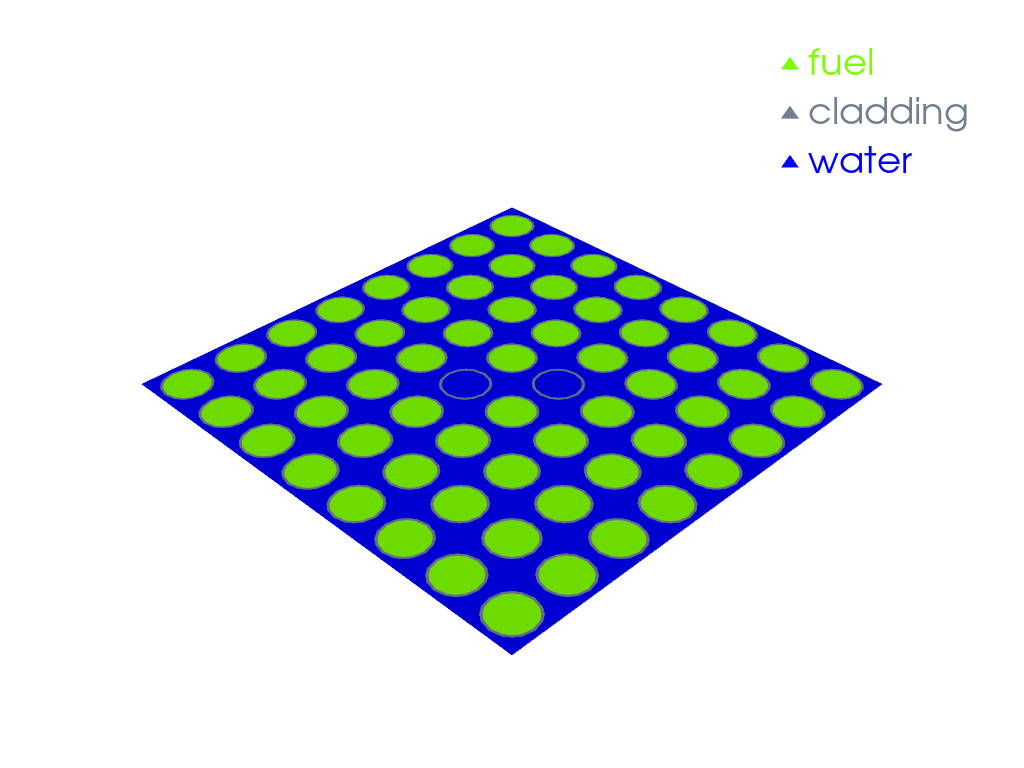

In [32]:
Text_sections[Text_sections.index("""final_generator=Fuel_pin""")]="""final_generator=Bundle_Mesh"""
run_code()

# 5. Make Fuel Assemblies
We need to turn the fuel bundle and control rod meshes into more complex assemblies, for ease of use further down the line, but also from an abstraction point of view, as if needed, we could put in a simpler mesh in place of these assemblies later, and the downstream infrastructure wouldn't notice

### &ensp;&ensp;A. Create Quad Bundle

#### &ensp;&ensp;&ensp;&ensp;1. Setup

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;We need a reflection of Bundle_Mesh

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Call this block Bundle_flip

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;It is a SymmetryTransformGenerator across normal vector 0 1 0 at the origin

#### &ensp;&ensp;&ensp;&ensp;2. Construct base quad-bundle control rod mesh

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Due to the fact that the control rod is not a nice rectangle, and we want it in between the four bundles, we cannot do a CartesianPatterenedMeshGenerator

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;We use a new block type called a FlexiblePatternGenerator, which allows us to freely position objects inside a boundary, and then fills in the gaps. It supports rectangular patterns, which we will use for the bundles, and then we will use one more to place the control rod in the center

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;For setting it up, we want a cartesian boundary of size Wassem, and number of sectors nquad.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;For the inputs, do it in this order: Bundle_Mesh Bundle_flip cruciform_mesh (indexes 0 1 2)

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;For patterns, we want three rectangular patterns, which are separated with |

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;two of these (explained why in a minute)

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp; 0; 

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp; 1|

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;and one of these

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp; 3 2 3

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;**Note:** When given indexes greater than the number of available meshes, FlexiblePatternGenerator leaves an empty space, but it still spaces other mesh elements as if there was something there

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;The origins is where that "doubled" pattern comes into play. When you look at the assembly, you want the two water pins to always be across the diagonal pointing from the center. This means that the upper right and lower left bundle mesh are the same, just rotated over the middle.This also means we can just generate two of the same pattern next to one another, and just rotate one 180 degrees. To that end, the first pattern will be offset one Boffset in the positive x direction, and the other Boffset in the negative x direction.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;For pitches both x and y we want 'Bpitch Bpitch 0', as the control rod "blanks" we do not want to interfere with anything else

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;The strategy mentioned earlier is completed when we have the second of the 1 0 patterns flipped 180 degrees under rect_rotations

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Desired area is just how small the generator makes the triangles it generates to fill in the gaps

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Background is subdomain water, ID 4

### &ensp;&ensp;B. Create Single Bundle

#### &ensp;&ensp;&ensp;&ensp;1. Create single bundle surround

&ensp;&ensp;&ensp;&ensp;We will be making a singule bundle mesh, where on corner is occupied by a fuel bundle and water surround, the rest is dummy space, as we don't want the rest of the volume of the assembly to "stick out" of the mesh

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;This will also be a FlexiblePattern..., called Bundle_singleRT_part

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;It will use Bundle_Mesh as its only input, and a pattern of '0'.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;It will have boundary_size Wsingle, and sectors nsingle

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;We will then make a block, Bundle_singleRT_mov, a TransformGenerator

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;It will TRANSLATE with a vector value of Boffset Boffset 0

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;We will also make another block called Bundle_singleLT_mov, which is a SymmertyTransformGenerator of Bundle_singleRT_mov with '1 0 0' over the origin. This is used later

#### &ensp;&ensp;&ensp;&ensp;2. Make the dummy Mesh for the rest of the assembly volume

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;When we assemble the core, we need to use a PatternCartesian... , which means we need meshes of the same size, so we can't just throw in single fuel bundles, we need to fill out the assembly shape. We will start with the fuel cell in the top right, or singleRT

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;We will do this with a Dummy Mesh block, sized to the rest of the assembly shape

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;The first step is making a 2d outline, using a PolyLineMeshGenerator, which does just that. We are trying to make a square with a smaller square cut out, so it should be 6 points. They need to be the main corners (-Rassem,+/-Rassem) and (Rassem, -Rassem), and the inner corners (Doffset, Doffset), (Doffset, Rassem). Make sure to also set loop = true. Block name is Dummy_boudnary_singleRT

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;We will then fill in this outline with an XYDelaunayGenerator, which is what FlexiblePatternGenerator uses to fill in its gaps. It will have block name Dummy_fill_singleRT. It will pull in the boundary we just made, and output to subdomain Dummy, ID 6.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Now is where we will begin a series of steps which are executed for the RT mesh, but reflected for the RB,LT,and LB meshes over different normal vectors.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;The first is to use a StitchMeshGenerator and combine the Dummy_fill_singleRT with Bundle_singleRT_mov.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Next and finally is Adding metadata, or pieces of information attached to the mesh that is needed for PatternCartesian, as FlexiblePattern does not add them for us, even though we made a cartesian outer bound which is perfectly compatible with PatternCartesian. Not addind this important info is one of the main downsides of using FlexiblePattern to create assembly meshes. We can do this with the aptly named AddMetaDataGenerator. We need to add 4 pieces of information: the width of the mesh (aka the pitch), whether or not is is a control drum, if the edge of the mesh can be cut into symmetrical pieces(trimmed), and if the center be trimmed. The first info is a real_scalar, with value Wassem. The other are boolean_scalar values, which should be set to false false true.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;The single bundle meshes are now ready

#### &ensp;&ensp;&ensp;&ensp;3. Make the double bundle meshes

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;The approach is the exact same to making single meshes, but we start with the top two bundles present, or doubleT.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;We can reuse Bundle_singleRT_mov and Bundle_singleLT_mov, but we need one more part. We want there to be water between them, not Dummy area, so we will make another polyline mesh, called gapT, to accomplish this.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;When making this polyline, I kept getting errors related to the number of sectors for some reason. I ended up having to hardcode a point every 2 units to finally get it to work. This is the part of this mesh not done parametrically, as the number of variables needed would be insane, and you cannot do math inside the \[MESH\] block, it would all have to be done externally, and substituion variables do not do arrays?? (Idk maybe). Anyway

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;We will then use the XYdelaunay and StitchMeshGenerators to fill in the gap, and then assemble the combined useful section of the doubleT mesh. 

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Next, we will make the polyline for the dummy boundary, which is now just a nice rectangle, and fill it with XYDelaunay.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Finally we will stitch the dummy and useful sections together. 

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Now, like before, the following are also created for doubleR, doubleB, and doubleL.

&ensp;&ensp;&ensp;&ensp;&ensp;&ensp;Like before, we must add MetaData, which will be the exact same as what we added for the single meshes


In [33]:
assembly_make="""
#Now begin making Assembly, containing four bundles and a control rod

  #Flip the bundle mesh to get the top left mesh
  [Bundle_flip]
    type = SymmetryTransformGenerator
    mirror_normal_vector = '0 1 0'
    mirror_point = '0 0 0'
    input = 'Bundle_Mesh'
  []

  #Construct the four bundle, control rod combined mesh
  [Bundle_quad]
    type = FlexiblePatternGenerator
    boundary_type = CARTESIAN
    boundary_size = ${Wassem} #Defined in terms of bundle sizes in variable section
    boundary_sectors = ${nquad}
    inputs = 'Bundle_Mesh Bundle_flip cruciform_mesh'
    rect_patterns = '0;
                     1|
                     0;
                     1|
                     3 2 3'
                     #Define patterns of meshes, note the first one is repeated
                     #Notice the index 3 on the last pattern, putting any index higher than the max provided (we have 0-2) will be interpreted as blank space
    rect_origins = ' ${Boffset} 0 0
                    -${Boffset} 0 0
                        0  0 0'
                    #We then put one of those repeated meshes on the right, and one on the left
    rect_pitches_x = '${Bpitch} ${Bpitch} 1'
    rect_pitches_y = '${Bpitch} ${Bpitch} 1'
    rect_rotations = '0.0 180.0 0.0'
    desired_area = 5
    background_subdomain_id = 4
    background_subdomain_name = 'water'
  []


  # BWRS need some assemblies for the edges of the core that don't contain a control rod, and only one or tow bundles

  #Section of the edge assemblies with single fuel bundles

  #Create fuel bundle for top right
  [Bundle_singleRT_part]
    type = FlexiblePatternGenerator
    boundary_type = CARTESIAN
    boundary_size = ${Wsingle}
    boundary_sectors = ${nsingle}
    inputs = 'Bundle_Mesh'
    rect_patterns = '0'
    rect_origins = '0 0 0'
    rect_pitches_x = '1'
    rect_pitches_y = '1'
    rect_rotations = '0.0'
    desired_area = 5
    background_subdomain_id = 4
    background_subdomain_name = 'water'
    external_boundary_name = "bundle_ext2"
    external_boundary_id = 999
  []

  #Then move it out of the center to it's correct spot in the "corner" of the space
  [Bundle_singleRT_mov]
    type = TransformGenerator
    input = Bundle_singleRT_part
    transform = TRANSLATE
    vector_value = '${Boffset} ${Boffset} 0'
  []

  #Do this for the Left side bundle as well by reflecting over the x axis
  [Bundle_singleLT_mov]
    type = SymmetryTransformGenerator
    mirror_normal_vector = '1 0 0'
    mirror_point = '0 0 0'
    input = 'Bundle_singleRT_mov'
  []

  #To properly make the core later, we need to fill the empty space in the assembly with dummy space

  #Generate boudnary for dummy space of single bundle in top right
  [Dummy_boundary_singleRT]
    # The two notch segments are 42 long; 20 added nodes -> 21 intervals of
    # exactly 2.0, which now matches the bundle patch node pitch.
    type = PolyLineMeshGenerator
    points = '${Soffset}  ${Soffset} 0
              ${Soffset}   ${Rassem} 0
              -${Rassem} ${Rassem} 0
              -${Rassem} -${Rassem} 0
              ${Rassem} -${Rassem} 0
              ${Rassem} ${Rassem} 0
    '
    loop = true
  []

  #Now fill in that dummy space
  [Dummy_fill_singleRT]
    type = XYDelaunayGenerator
    boundary = 'Dummy_boundary_singleRT'
    add_nodes_per_boundary_segment = 20
    refine_boundary = false
    desired_area = 10
    output_boundary = 'Dummy_boundRT'
    output_subdomain_id = 6
    output_subdomain_name = 'Dummy'
  []

  #Now combine the actual fuel bundle and the dummy area
  [Bundle_singleRT_combo]
    type = StitchMeshGenerator
    inputs = "Dummy_fill_singleRT Bundle_singleRT_mov"
    stitch_boundaries_pairs = 'Dummy_boundRT bundle_ext2'
    clear_stitched_boundary_ids = true
  []

  #Now flip over the x axis to get a single bundle in the bottom right
  [Bundle_singleRB_combo]
    type = SymmetryTransformGenerator
    mirror_normal_vector = '0 1 0'
    mirror_point = '0 0 0'
    input = 'Bundle_singleRT_combo'
  []

  #Flip single top right over y axis to get single top left
  [Bundle_singleLT_combo]
    type = SymmetryTransformGenerator
    mirror_normal_vector = '1 0 0'
    mirror_point = '0 0 0'
    input = 'Bundle_singleRT_combo'
  []

  #Flip single top left over x axis to get bottom left
  [Bundle_singleLB_combo]
    type = SymmetryTransformGenerator
    mirror_normal_vector = '0 1 0'
    mirror_point = '0 0 0'
    input = 'Bundle_singleLT_combo'
  []

  #The way we created these is incompatible with later tools, so we need to add metadata to make it usable by later generators
  [Bundle_singleRT]
    type = AddMetaDataGenerator
    input = Bundle_singleRT_combo

    # Define pitch for PatternedCartesianMeshGenerator
    real_scalar_metadata_names = 'pattern_pitch_meta'
    real_scalar_metadata_values = ${Wassem}

    boolean_scalar_metadata_names = 'is_control_drum_meta peripheral_trimmability center_trimmability'
    boolean_scalar_metadata_values = 'false false true'
  []

  #Add the MetaData for left top mesh
  [Bundle_singleLT]
    type = AddMetaDataGenerator
    input = Bundle_singleLT_combo

    # Define pitch for PatternedCartesianMeshGenerator
    real_scalar_metadata_names = 'pattern_pitch_meta'
    real_scalar_metadata_values = ${Wassem}

    boolean_scalar_metadata_names = 'is_control_drum_meta peripheral_trimmability center_trimmability'
    boolean_scalar_metadata_values = 'false false true'
  []

  #Add the MetaData for right bottom mesh
  [Bundle_singleRB]
    type = AddMetaDataGenerator
    input = Bundle_singleRB_combo

    # Define pitch for PatternedCartesianMeshGenerator
    real_scalar_metadata_names = 'pattern_pitch_meta'
    real_scalar_metadata_values = ${Wassem}

    boolean_scalar_metadata_names = 'is_control_drum_meta peripheral_trimmability center_trimmability'
    boolean_scalar_metadata_values = 'false false true'
  []

  #Add the MetaData for left bottom mesh
  [Bundle_singleLB]
    type = AddMetaDataGenerator
    input = Bundle_singleLB_combo

    # Define pitch for PatternedCartesianMeshGenerator
    real_scalar_metadata_names = 'pattern_pitch_meta'
    real_scalar_metadata_values = ${Wassem}

    boolean_scalar_metadata_names = 'is_control_drum_meta peripheral_trimmability center_trimmability'
    boolean_scalar_metadata_values = 'false false true'
  []


  #Now begin creating assemblies with two bundles next to each other, on top, bottom, on the right, and on the left

  #Create the boundary that exists between two single fuel bundles where a control rod normally is, as we need to fill that with water
  [Bundle_gapT_boundary]
    type = PolyLineMeshGenerator
    loop = true
    # We need to match the number of line segments on the edges of the fuel bundles with this filler, so we must define lots of points by hand : (
    points = '2 44 0
              0 44 0
              -2 44 0
              -2 42 0
              -2 40 0
              -2 38 0
              -2 36 0
              -2 34 0
              -2 32 0
              -2 30 0
              -2 28 0
              -2 26 0
              -2 24 0
              -2 22 0
              -2 20 0
              -2 18 0
              -2 16 0
              -2 14 0
              -2 12 0
              -2 10 0
              -2 8 0
              -2 6 0
              -2 4 0
              -2 2 0
              0 2 0
              2 2 0
              2 4 0
              2 6 0
              2 8 0
              2 10 0
              2 12 0
              2 14 0
              2 16 0
              2 18 0
              2 20 0
              2 22 0
              2 24 0
              2 26 0
              2 28 0
              2 30 0
              2 32 0
              2 34 0
              2 36 0
              2 38 0
              2 40 0
              2 42 0'
  []

  #Now we fill in that gap
  [Bundle_gapT_fill]
    type = XYDelaunayGenerator
    boundary = 'Bundle_gapT_boundary'
    add_nodes_per_boundary_segment = 0
    refine_boundary = false
    desired_area = 5
    output_boundary = 'bundle_bound_gapT'
    output_subdomain_id = 4
    output_subdomain_name = 'water'
  []

  #Now we combine the gap and the left top and right top fuel bundles to create a double bundle mesh for the top of an assembly
  [Bundle_doubleT_part]
    type = StitchMeshGenerator
    inputs = 'Bundle_singleLT_mov Bundle_gapT_fill Bundle_singleRT_mov'
    stitch_boundaries_pairs = 'bundle_ext2 bundle_bound_gapT;bundle_bound_gapT bundle_ext2'
    clear_stitched_boundary_ids = true
  []

  #Create dummy boundary for rest of assembly
  [Dummy_boundary_doubleT]
    type = PolyLineMeshGenerator
    points = '${Rassem}  -${Rassem} 0
              ${Rassem}   ${Soffset} 0
              -${Rassem} ${Soffset} 0
              -${Rassem} -${Rassem} 0
    '
    loop = true
  []

  #fill in dummy boundary
  [Dummy_fill_doubleT]
    type = XYDelaunayGenerator
    boundary = 'Dummy_boundary_doubleT'
    add_nodes_per_boundary_segment = ${ndummy}
    refine_boundary = false
    desired_area = 10
    output_boundary = 'Dummy_boundT'
    output_subdomain_id = 6
    output_subdomain_name = 'Dummy'
  []

  #Now we stitch together top and bottom of assembly
  [Bundle_doubleT_combo]
    type = StitchMeshGenerator
    inputs = "Dummy_fill_doubleT Bundle_doubleT_part"
    stitch_boundaries_pairs = 'Dummy_boundT bundle_ext2'
    clear_stitched_boundary_ids = true
  []

  #Now we can just rotate the top double bundle to get the rest

  [Bundle_doubleL_combo]
    type = TransformGenerator
    input = Bundle_doubleT_combo
    transform = ROTATE
    vector_value = '0 0 90'
  []
  [Bundle_doubleB_combo]
    type = TransformGenerator
    input = Bundle_doubleL_combo
    transform = ROTATE
    vector_value = '0 0 90'
  []
  [Bundle_doubleR_combo]
    type = TransformGenerator
    input = Bundle_doubleB_combo
    transform = ROTATE
    vector_value = '0 0 90'
  []

  #We must once again attach metadata to all 4 meshes
  [Bundle_doubleT]
    type = AddMetaDataGenerator
    input = Bundle_doubleT_combo

    # Define pitch dimensions for CartesianPatternedMeshGenerator
    real_scalar_metadata_names = 'pattern_pitch_meta'
    real_scalar_metadata_values = ${Wassem}

    boolean_scalar_metadata_names = 'is_control_drum_meta peripheral_trimmability center_trimmability'
    boolean_scalar_metadata_values = 'false false true'
  []
  [Bundle_doubleR]
    type = AddMetaDataGenerator
    input = Bundle_doubleR_combo

    # Define pitch dimensions for CartesianPatternedMeshGenerator
    real_scalar_metadata_names = 'pattern_pitch_meta'
    real_scalar_metadata_values = ${Wassem}

    boolean_scalar_metadata_names = 'is_control_drum_meta peripheral_trimmability center_trimmability'
    boolean_scalar_metadata_values = 'false false true'
  []
  [Bundle_doubleB]
    type = AddMetaDataGenerator
    input = Bundle_doubleB_combo

    # Define pitch dimensions for CartesianPatternedMeshGenerator
    real_scalar_metadata_names = 'pattern_pitch_meta'
    real_scalar_metadata_values = ${Wassem}

    boolean_scalar_metadata_names = 'is_control_drum_meta peripheral_trimmability center_trimmability'
    boolean_scalar_metadata_values = 'false false true'
  []
  [Bundle_doubleL]
    type = AddMetaDataGenerator
    input = Bundle_doubleL_combo

    # Define pitch dimensions for CartesianPatternedMeshGenerator
    real_scalar_metadata_names = 'pattern_pitch_meta'
    real_scalar_metadata_values = ${Wassem}

    boolean_scalar_metadata_names = 'is_control_drum_meta peripheral_trimmability center_trimmability'
    boolean_scalar_metadata_values = 'false false true'
  []

  #We have now created all assemblies we need to make a core!!!

"""
if assembly_make in Text_sections:
  pass
else:
  Text_sections.insert(5,assembly_make)

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1055, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=
 and              Node id()=2110, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=

Stitching nodes   Node id()=1055, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=
 and              Node id()=2110,

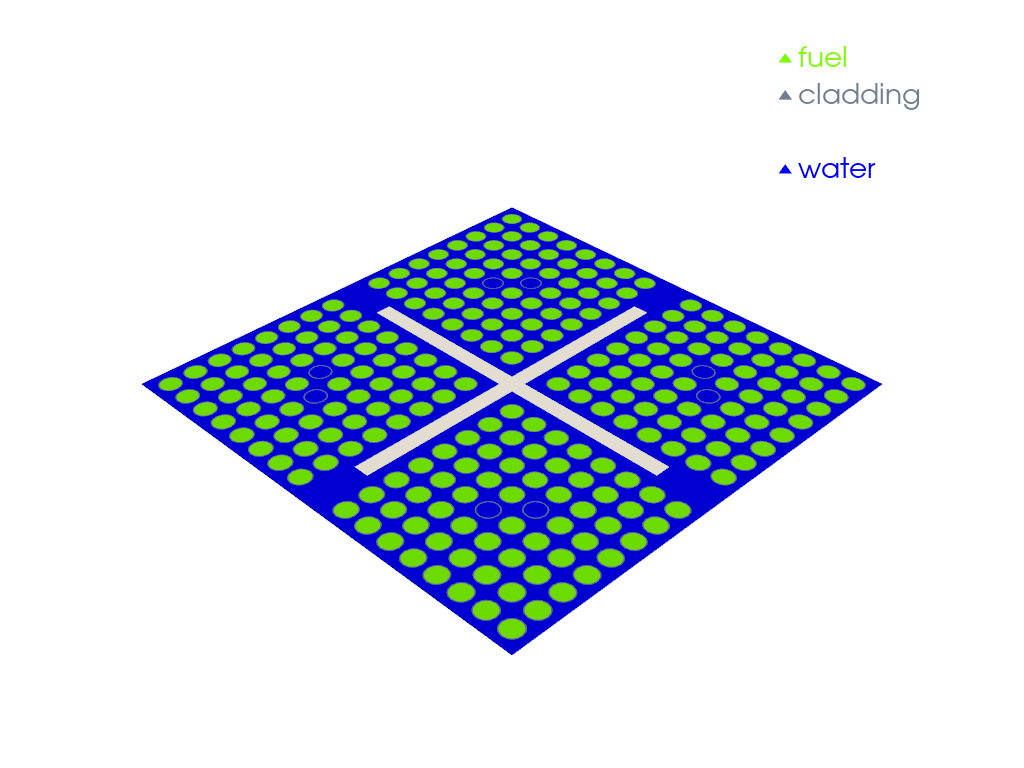

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1055, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=
 and              Node id()=2110, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=

Stitching nodes   Node id()=1055, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=
 and              Node id()=2110,

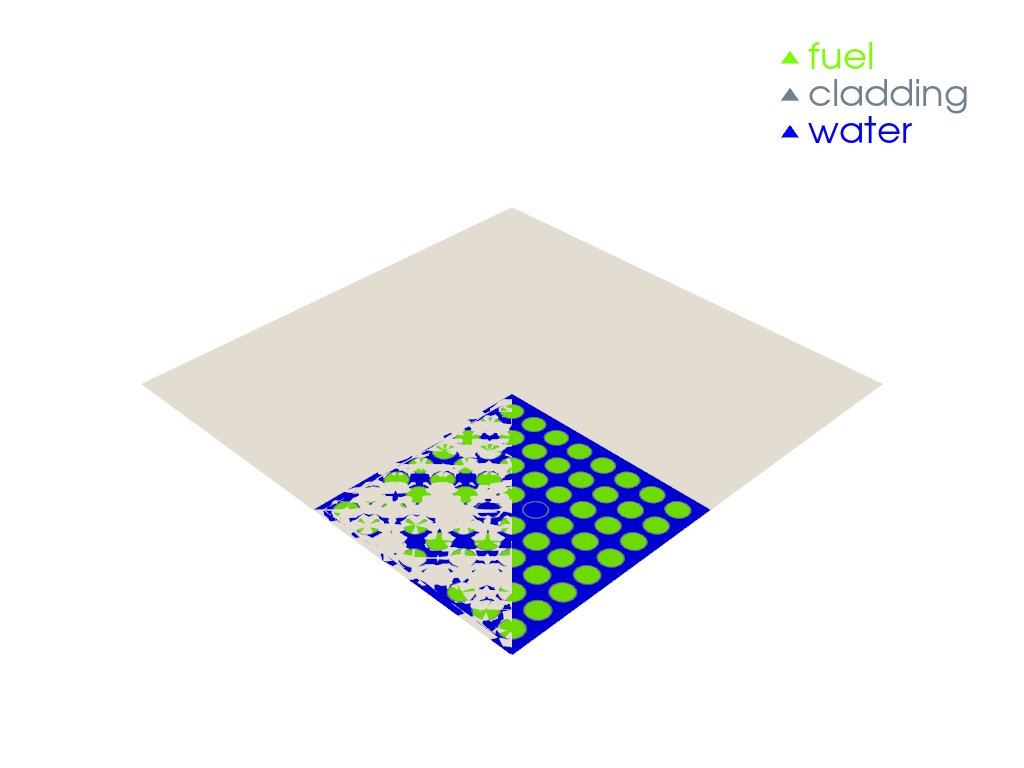

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1054, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=
 and              Node id()=2111, processor_id()=0, Point=(x,y,z)=(-18.4072,  19.3144,        0)
    DoFs=

Stitching nodes   Node id()=1055, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=
 and              Node id()=2110, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=

Stitching nodes   Node id()=1055, processor_id()=0, Point=(x,y,z)=(-18.9344,  18.9344,        0)
    DoFs=
 and              Node id()=2110,

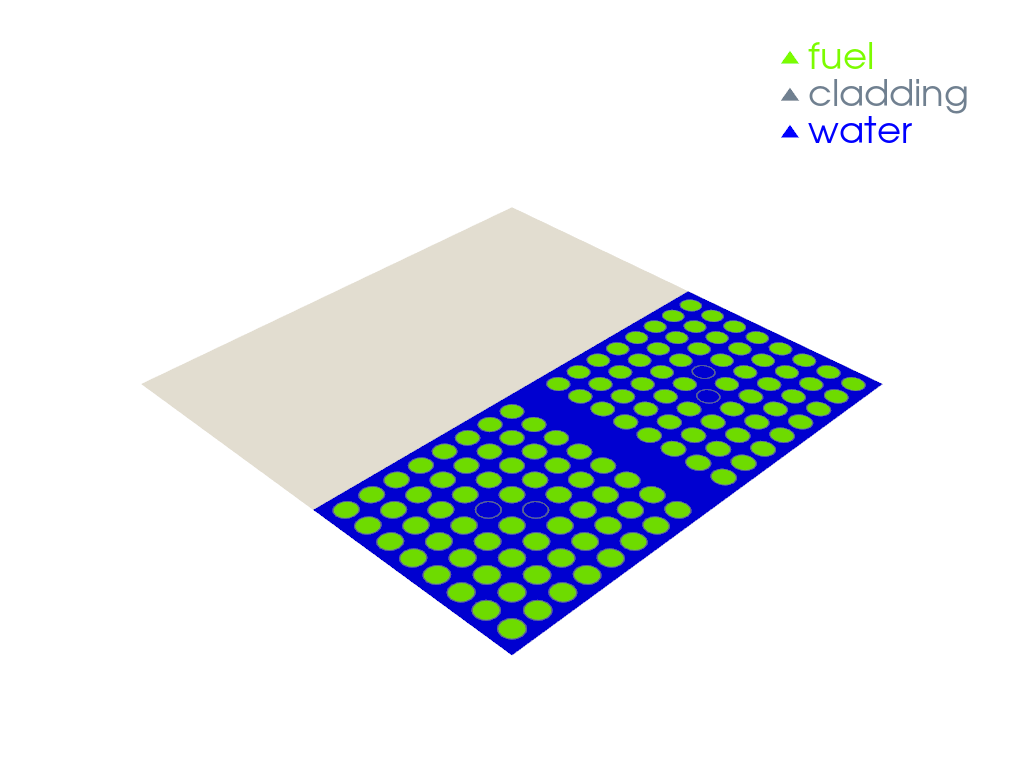

In [34]:
Text_sections[Text_sections.index("""final_generator=Bundle_Mesh""")]="""final_generator=Bundle_quad"""
run_code()
Text_sections[Text_sections.index("""final_generator=Bundle_quad""")]="""final_generator=Bundle_singleRT"""
run_code()
Text_sections[Text_sections.index("""final_generator=Bundle_singleRT""")]="""final_generator=Bundle_doubleT"""
run_code()